In [13]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV 
from sklearn.dummy import DummyRegressor 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler, PolynomialFeatures 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("lab_ticket_resolution.csv") 
print(df.shape) 
print(df.dtypes) 
print(df.describe(include="all")) 
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

In [14]:
X = df[["complexity_score", "team_experience_years"]] #features that are used for prediction
y = df["resolution_hours"]
print("Features selected:", list(X.columns))
print("Target variable: resolution_hours")

Features selected: ['complexity_score', 'team_experience_years']
Target variable: resolution_hours


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#20% for training data and 80% for test data, splitted randomly
print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (192, 2)
Testing set shape: (48, 2)


In [16]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_model = Ridge(alpha=1.0)
cv_scores = cross_val_score(
    ridge_model, 
    X_train, 
    y_train, 
    cv=kf, 
    scoring='neg_mean_absolute_error'
)

print(f"Cross-Validation MAE scores across 5 folds: {-cv_scores}")
print(f"Mean CV MAE: {-cv_scores.mean():.4f}")

Cross-Validation MAE scores across 5 folds: [3.30949981 3.0754415  3.66614425 3.11574978 2.67426995]
Mean CV MAE: 3.1682


In [17]:
# Fit baseline
dummy = DummyRegressor(strategy='mean')
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

# Evaluate
dummy_mae = mean_absolute_error(y_test, y_pred_dummy)
dummy_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
dummy_r2 = r2_score(y_test, y_pred_dummy)

print("Dummy Regressor Test Metrics:")
print(f"MAE:  {dummy_mae:.4f}")
print(f"RMSE: {dummy_rmse:.4f}")
print(f"R2:   {dummy_r2:.4f}")

Dummy Regressor Test Metrics:
MAE:  9.1140
RMSE: 10.5977
R2:   -0.0210


In [18]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

# Evaluate
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
lr_r2 = r2_score(y_test, y_pred_lr)

print("Linear Regression Test Metrics:")
print(f"MAE:  {lr_mae:.4f}")
print(f"RMSE: {lr_rmse:.4f}")
print(f"R2:   {lr_r2:.4f}")

Linear Regression Test Metrics:
MAE:  2.9060
RMSE: 3.5723
R2:   0.8840


In [19]:
for deg in [2, 3]:
    poly_pipe = make_pipeline(
        PolynomialFeatures(degree=deg),
        StandardScaler(),
        LinearRegression()
    )
    scores = cross_val_score(poly_pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
    print(f"Polynomial Degree {deg} - CV MAE: {-scores.mean():.4f} (+/- {scores.std():.4f})")

Polynomial Degree 2 - CV MAE: 3.1751 (+/- 0.1973)
Polynomial Degree 3 - CV MAE: 3.1320 (+/- 0.1432)


Here the better way would be using the linear regression model, because the dummy regression is completely blind guess and has very high MAE and RMSE with negative value of R2. The ploynomial regression are overfitting and memorise noises if the problem is not really complex, hence there is higher MAE for both degree 2 and 3 in our problem.

In [20]:
# Ridge Pipeline & Grid Search
ridge_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Ridge())
ridge_grid = GridSearchCV(ridge_pipe, {'ridge__alpha': [0.1, 1.0, 10.0, 100.0]}, cv=5, scoring='neg_mean_absolute_error')
ridge_grid.fit(X_train, y_train)

print(f"Best Ridge Alpha: {ridge_grid.best_params_}")
print(f"Best Ridge CV MAE: {-ridge_grid.best_score_:.4f}")

# Lasso Pipeline & Grid Search
lasso_pipe = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2), Lasso(max_iter=10000))
lasso_grid = GridSearchCV(lasso_pipe, {'lasso__alpha': [0.01, 0.1, 1.0, 10.0]}, cv=5, scoring='neg_mean_absolute_error')
lasso_grid.fit(X_train, y_train)

print(f"Best Lasso Alpha: {lasso_grid.best_params_}")
print(f"Best Lasso CV MAE: {-lasso_grid.best_score_:.4f}")

Best Ridge Alpha: {'ridge__alpha': 10.0}
Best Ridge CV MAE: 3.1712
Best Lasso Alpha: {'lasso__alpha': 0.01}
Best Lasso CV MAE: 3.1754


Here we built pipelines with StandardScaler and polynomial expansion (degree 2), followed by Ridge and Lasso regression. We used GridSearchCV to tune the regularization parameter $\alpha$. Ridge achieved a slightly lower error by smoothly scaling down coefficients, whereas Lasso achieved a nearly identical result by applying sparse feature selection with a very small penalty.

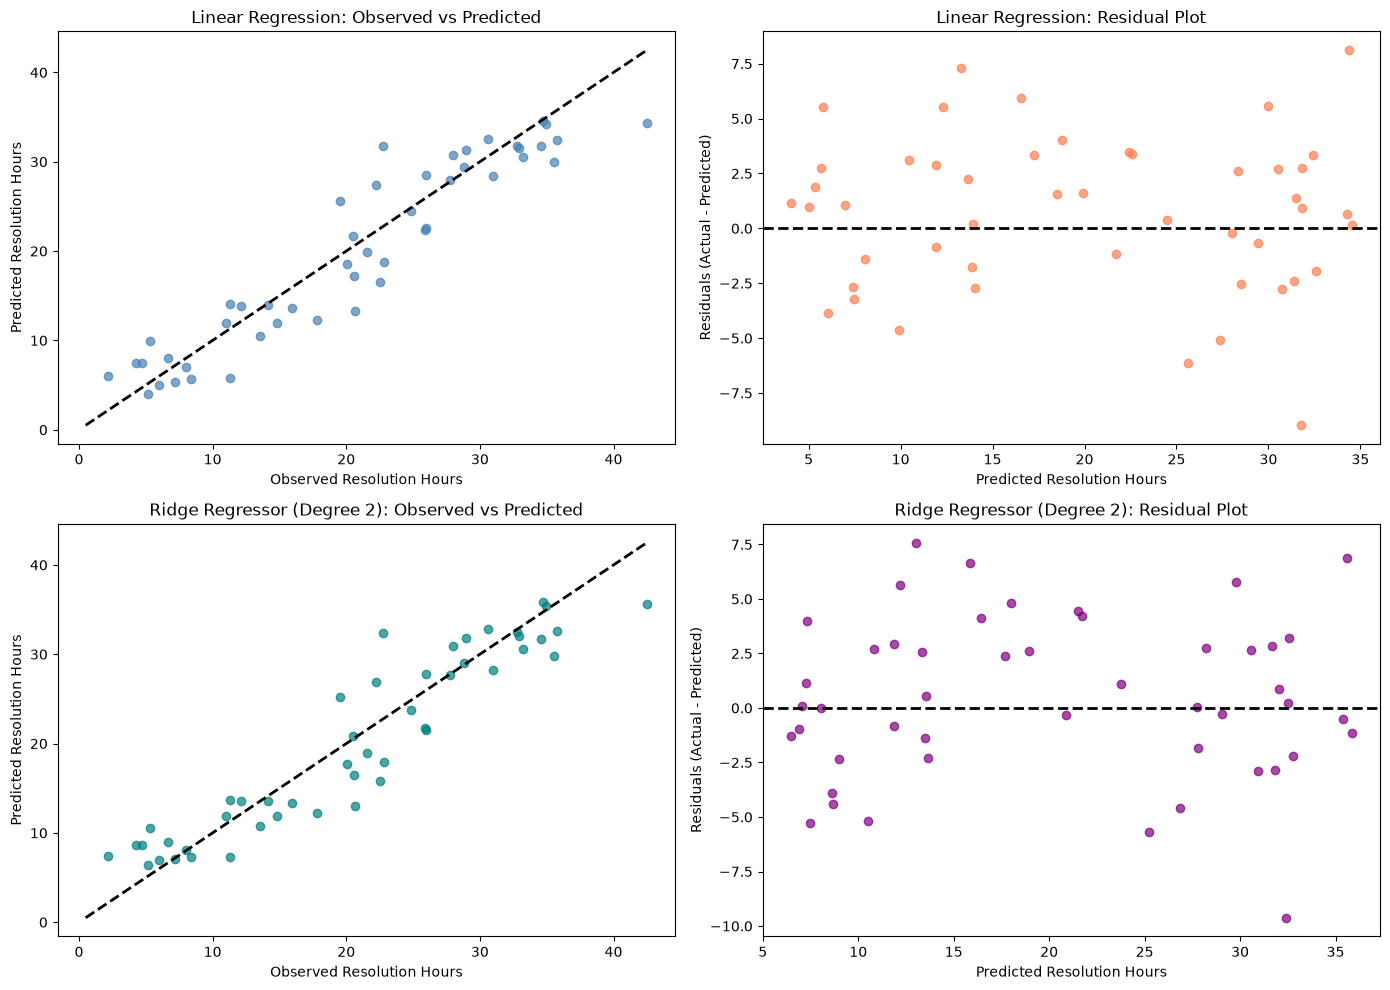

In [22]:
# 1. Predictions for both models
y_pred_lr = lr.predict(X_test)
y_pred_ridge = best_ridge.predict(X_test)

# 2. Set up a 2x2 grid of subplots (Model 1 on top, Model 2 on bottom)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Model 1: Standard Linear Regression ---
# Observed vs Predicted
axes[0, 0].scatter(y_test, y_pred_lr, alpha=0.7, color='steelblue')
axes[0, 0].plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
axes[0, 0].set_xlabel("Observed Resolution Hours")
axes[0, 0].set_ylabel("Predicted Resolution Hours")
axes[0, 0].set_title("Linear Regression: Observed vs Predicted")

# Residual Plot
residuals_lr = y_test - y_pred_lr
axes[0, 1].scatter(y_pred_lr, residuals_lr, alpha=0.7, color='coral')
axes[0, 1].axhline(0, color='k', linestyle='--', lw=2)
axes[0, 1].set_xlabel("Predicted Resolution Hours")
axes[0, 1].set_ylabel("Residuals (Actual - Predicted)")
axes[0, 1].set_title("Linear Regression: Residual Plot")


# --- Model 2: Ridge Regressor ---
# Observed vs Predicted
axes[1, 0].scatter(y_test, y_pred_ridge, alpha=0.7, color='teal')
axes[1, 0].plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
axes[1, 0].set_xlabel("Observed Resolution Hours")
axes[1, 0].set_ylabel("Predicted Resolution Hours")
axes[1, 0].set_title("Ridge Regressor (Degree 2): Observed vs Predicted")

# Residual Plot
residuals_ridge = y_test - y_pred_ridge
axes[1, 1].scatter(y_pred_ridge, residuals_ridge, alpha=0.7, color='purple')
axes[1, 1].axhline(0, color='k', linestyle='--', lw=2)
axes[1, 1].set_xlabel("Predicted Resolution Hours")
axes[1, 1].set_ylabel("Residuals (Actual - Predicted)")
axes[1, 1].set_title("Ridge Regressor (Degree 2): Residual Plot")

plt.tight_layout()
plt.show()

Here we plotted observed versus predicted values and a residual plot for Lenier regression and ridge regressor of degree 2.

## Analysis Questions

10. Mean baseline establishes an absolute minimum performance floor. Any learning model is expected to beat this.

11. The model with lowest MAE is the linear regression. MAE penalizes errors linearly, whereas RMSE squares errors, giving higher weight to large outliers and extreme errors.

12. Degree 2 polynomial features capture mild non-linear interactions well, but moving to Degree 3 significantly increases cross-validation error and variance, which is classic evidence of overfitting due to model complexity on a limited sample size.

13. Regularization penalizes large coefficients (L2 in Ridge, L1 sparsity/feature selection in Lasso), preventing overfitting on noisy interaction terms and stabilizing out-of-sample predictions.

14. Regularization penalizes the absolute size of coefficients. If features are on vastly different scales the penalty would unfairly crush features with larger numerical scales. StandardScaler ensures all features contribute equally to the penalty. 

15. lines_changed is a leakage risk because the exact number of lines modified is only known after the ticket is resolved. In a true predictive deployment scenario prior to starting work, this value is unknown.

16. Random split would not be appropriate if tickets were collected over several years or came from repeated customers/teams. If data has a temporal trend or clustered dependencies (repeated teams/customers) a random split causes data leakage by placing correlated samples into both train and test sets and that causes overly optimistic performance estimates.

17. Additional tests needed to be performed before deploying this model could be: out-of-time validation, check for demographic or team bias, test model robustness against missing feature inputs and establish continuous monitoring for concept drift.